# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [2]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [3]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,14.189159,7.205170,S-G1
1,1,osimertinib,B,tago-01560,1.031097,13.491245,P
2,2,osimertinib,A,tago-02253,14.651874,7.435656,S-G1
3,3,osimertinib,A,tago-01478,13.919818,-3.705924,S-syn
4,4,osimertinib,A,tago-02626,14.527276,6.953301,S-G1


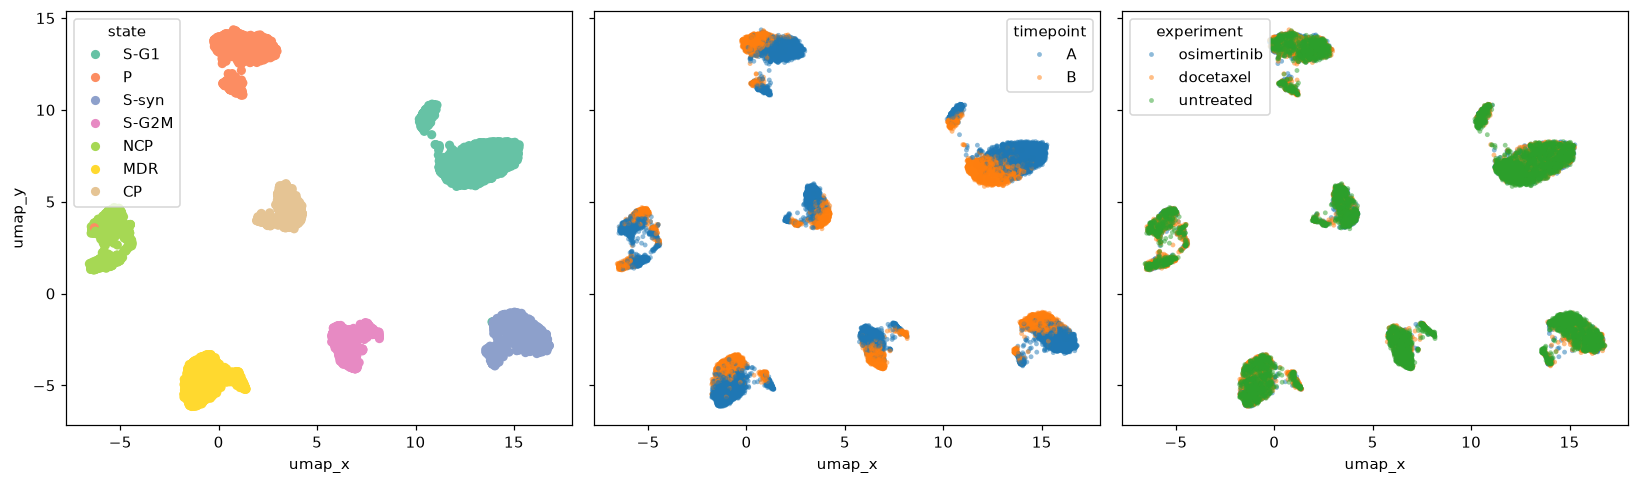

In [4]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [5]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [6]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [7]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [8]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [9]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [10]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

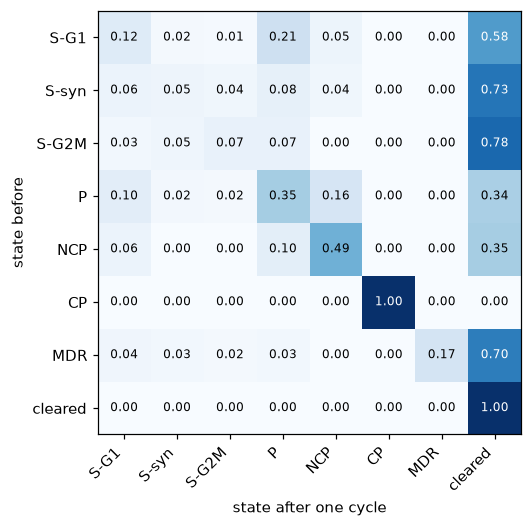

In [11]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

Q1

CP is also absorbing under osimertinib. Every observed CP cell stayed CP after one cycle, so the fitted matrix predicts that CP cells survive every round.

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

Q2

I predict that osimertinib will eventually clear cells starting in S-G1, S-syn, S-G2M, P, NCP, or MDR. Each has a path to cleared, and none can reach CP. Cells that start in CP will survive.

In [12]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [13]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [14]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

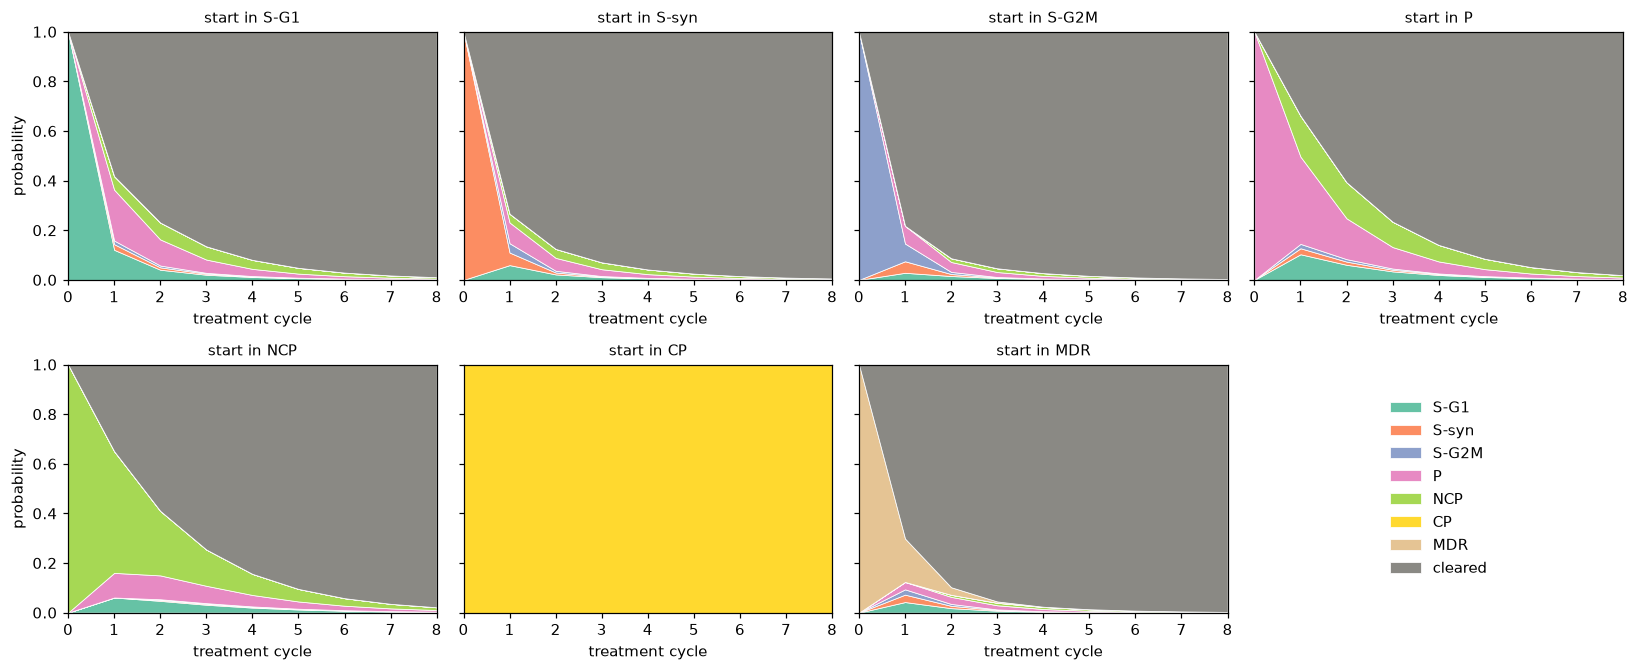

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [15]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



Q3

In [16]:
# Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?

survival = pd.DataFrame({
    s: 1 - evolve(basis(s, P_hat), P_hat, 8)[:, -1]
    for s in STATES
})

survival.index.name = "cycle"
survival.loc[[1, 3, 8]].round(5)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR
cycle,,,,,,,
1,0.41811,0.26652,0.21786,0.66154,0.65064,1.0,0.29851
3,0.13516,0.07071,0.04672,0.23436,0.25434,1.0,0.04508
8,0.01081,0.00562,0.00360,0.01903,0.02159,1.0,0.00295


The probability of being cleared approaches 100% for cells starting in S-G1, S-syn, S-G2M, P, NCP, or MDR. CP is the only starting state that survives indefinitely. At eight cycles, every other starting state still has some probability of survival.

Of the states that can be cleared, which tumor lasts the longest?

- Of the starting states that osimertinib can eventually clear, NCP lasts the longest. After eight cycles, a cell that started in NCP has a 2.16% probability of still being alive. This is the highest survival probability among the six starting states that can eventually be cleared.

In [17]:
# Which starting state sticks around for the most cycles of drug?
P_hat.loc["CP"]

state_B
S-G1       0.0
S-syn      0.0
S-G2M      0.0
P          0.0
NCP        0.0
CP         1.0
MDR        0.0
cleared    0.0
Name: CP, dtype: float64

CP is the starting state that sticks around for the most cycles of osimertinib. A cell starting in CP has a 100% probability of staying in CP each cycle.

In [18]:
# Which starting state results in the highest proportion of alive cells after three cycles?
survival.loc[3].sort_values(ascending=False).round(5)

CP       1.00000
NCP      0.25434
P        0.23436
S-G1     0.13516
S-syn    0.07071
S-G2M    0.04672
MDR      0.04508
Name: 3, dtype: float64

CP has the highest survival after three cycles (100%). Among the states that eventually clear, NCP has the highest survival (25.43%), followed by P (23.44%).

### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

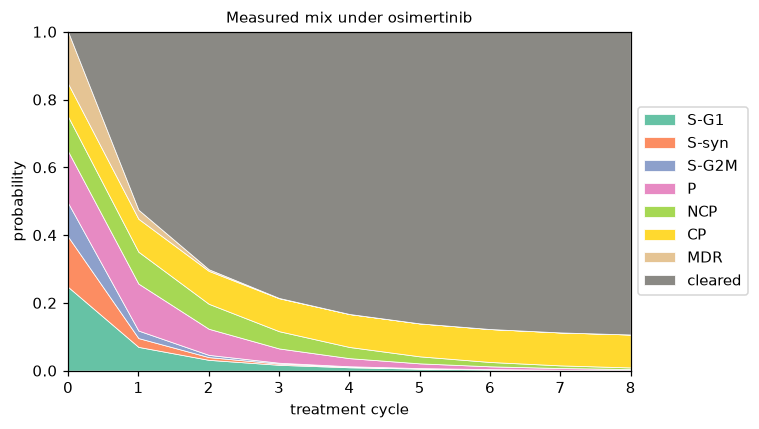

In [19]:
# Your code here

pi_mix = (cells.loc[cells["timepoint"] == "A", "state"]
          .value_counts(normalize=True)
          .reindex(OUTCOMES, fill_value=0)
          .to_numpy())

# evolve pi_mix and plot the results

mix_osi = evolve(pi_mix, P_hat, N_CYCLES)

fig, ax = plt.subplots(figsize=(7, 4))
plot_trajectory(mix_osi, ax, "Measured mix under osimertinib")
ax.set_ylabel("probability")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()

<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

Q4

CP dominates the remaining cluster. After eight cycles of osimertinib, about 91.2% of the surviving cells are in CP. These cells will never be cleared. The transition matrix predicts a long-run endpoint of 9.72% of the original cells in CP and 90.28% in cleared. Under osimertinib, every cell that starts in CP stays there. Cells in the other starting states cannot enter CP and eventually reach cleared.

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [20]:
##Add code here
# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position

def transition_matrix(experiment):
    sample = cells.loc[cells["experiment"] == experiment]
    at_A = sample.loc[sample["timepoint"] == "A", ["lineage_tag", "state"]]
    at_B = sample.loc[sample["timepoint"] == "B", ["lineage_tag", "state"]]

    pairs = at_A.merge(
        at_B, on="lineage_tag", how="left",
        suffixes=("_A", "_B"), validate="one_to_one")
    
    next_state = pairs["state_B"].fillna("cleared")

    matrix = (pd.crosstab(pairs["state_A"], next_state, normalize="index")
              .reindex(index=OUTCOMES, columns=OUTCOMES, fill_value=0))
    matrix.loc["cleared", "cleared"] = 1

    assert np.allclose(matrix.sum(axis=1), 1)
    return matrix.to_numpy()

P_osi = P_hat.to_numpy()

P_doc = transition_matrix("docetaxel")       # TODO

P_holiday = transition_matrix("untreated")   # TODO

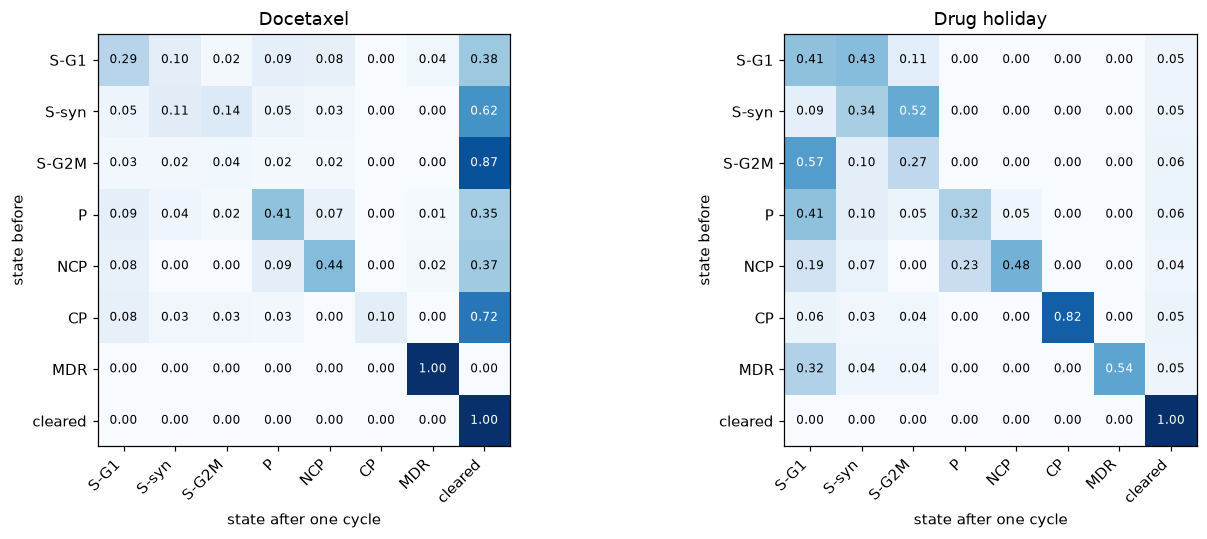

In [21]:
#Plot the transition matrices for docetaxel and the drug holiday.

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, matrix, title in zip(axes, [P_doc, P_holiday], ["Docetaxel", "Drug holiday"]):
    show_matrix(pd.DataFrame(matrix, index=OUTCOMES, columns=OUTCOMES), title, ax)

plt.tight_layout()
plt.show()

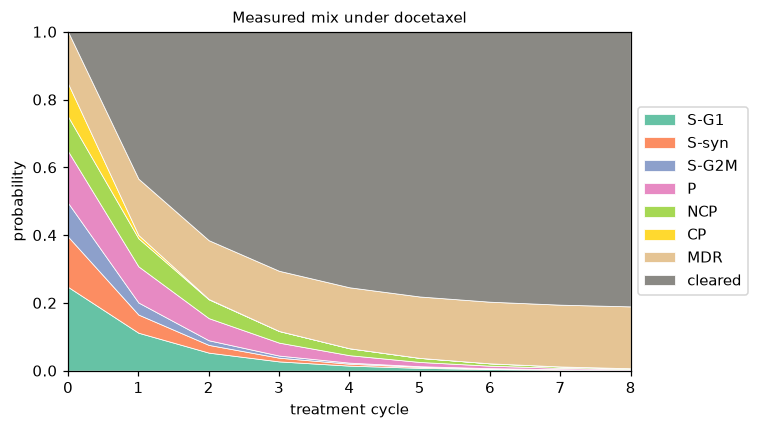

S-G1       0.00152
S-syn      0.00056
S-G2M      0.00031
P          0.00237
NCP        0.00231
CP         0.00000
MDR        0.18257
cleared    0.81037
dtype: float64

In [22]:
# Simulate the evolution of pi_mix under docetaxel

mix_doc = evolve(pi_mix, P_doc, N_CYCLES)

fig, ax = plt.subplots(figsize=(7, 4))
plot_trajectory(mix_doc, ax, "Measured mix under docetaxel")
ax.set_ylabel("probability")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

pd.Series(mix_doc[-1], index=OUTCOMES).round(5)

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?

2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

Under docetaxel, MDR is absorbing, and 72.41% of CP cells clear in one cycle. Under osimertinib, CP is absorbing, and 70.1% of MDR cells clear in one cycle. During a drug holiday, no living state is absorbing. For example, 31.94% of MDR cells move to S-G1 in one cycle. The cleared state is absorbing in all three matrices. After eight rounds, 81.04% of the original cells are cleared. MDR grows from 15.30% to 18.26% of the original tumor and accounts for about 96% of the surviving cells.

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

In [23]:
## Add code here

drugs = {"O": P_osi, "D": P_doc, "H": P_holiday}
schedules = ["O" * 8, "D" * 8, "OD" * 4, "DO" * 4, "H" + "D" * 7]

starts = {
    "measured mix": pi_mix,
    "all CP": basis("CP", P_hat),
    "all MDR": basis("MDR", P_hat),
    "all S-G2M": basis("S-G2M", P_hat),
}

rows = []
for start, pi0 in starts.items():
    for schedule in schedules:
        pi = pi0.copy()
        first_99 = None
        for cycle, drug in enumerate(schedule, start=1):
            pi = pi @ drugs[drug]
            if first_99 is None and pi[-1] >= 0.99:
                first_99 = cycle
        rows.append([start, schedule, 100 * pi[-1], first_99])

plans = pd.DataFrame(rows, columns=["start", "schedule", "% cleared at 8", "first cycle at 99%"])
display(plans.pivot(index="start", columns="schedule", values="% cleared at 8").round(3))
plans.pivot(index="start", columns="schedule", values="first cycle at 99%").astype("Int64")

schedule,DDDDDDDD,DODODODO,HDDDDDDD,ODODODOD,OOOOOOOO
start,,,,,
all CP,98.991,99.643,98.457,99.361,0.000
all MDR,0.000,99.273,43.166,99.524,99.705
all S-G2M,99.412,99.795,95.095,99.682,99.640
measured mix,81.037,99.084,87.800,99.059,89.335


schedule,DDDDDDDD,DODODODO,HDDDDDDD,ODODODOD,OOOOOOOO
start,,,,,
all CP,<NA>,7,<NA>,8,<NA>
all MDR,<NA>,8,<NA>,7,6
all S-G2M,6,6,<NA>,6,6
measured mix,<NA>,8,<NA>,8,<NA>


We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

For the measured mix, eight rounds of docetaxel clear 81.037% of the original cells, and eight rounds of osimertinib clear 89.335%. Alternating for four pairs (eight rounds) clears just over 99% because each drug can clear cells that resist the other. For this tumor, the starting drug makes only a small difference. Starting with docetaxel clears 99.084% after eight rounds, compared with 99.059% starting with osimertinib. A drug holiday helps when the tumor starts entirely in MDR and the available drug is docetaxel. MDR is absorbing under docetaxel, but some cells leave MDR during a holiday. One holiday followed by seven docetaxel rounds clears 43.17% of the original cells, compared with 0% for eight docetaxel rounds alone.

I used 99% expected cell clearance as my target and chose the fewest rounds that reached it among the schedules tested.

- Measured Mix: Alternate for eight rounds, starting with docetaxel. Neither drug alone reaches 99%, and this order gives the highest clearance.
- All CP: Alternate for seven rounds, starting with docetaxel. CP is absorbing under osimertinib, and alternating in this order reaches 99% one round sooner than starting with osimertinib.
- All MDR: Use osimertinib for six rounds. It reaches 99%, while docetaxel alone leaves every MDR cell in MDR.
- All S-G2M:  Use docetaxel for six rounds. It reaches 99% as quickly as either alternating schedule.

## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [24]:
rng = np.random.default_rng(100)

In [25]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [26]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

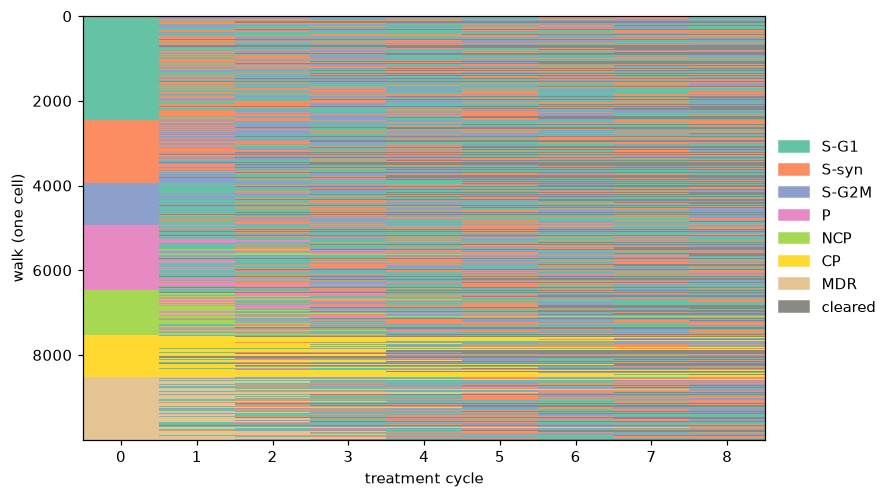

In [27]:
N_WALKS = 10_000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [28]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

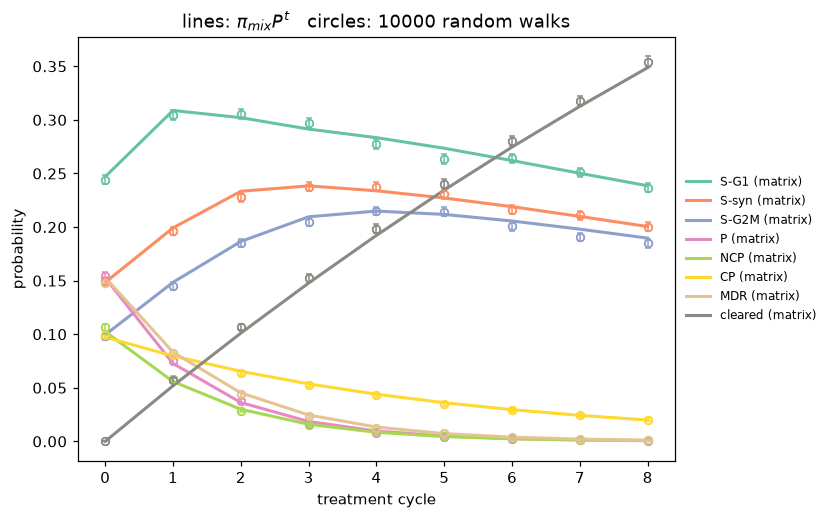

In [29]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

### Original Outputs

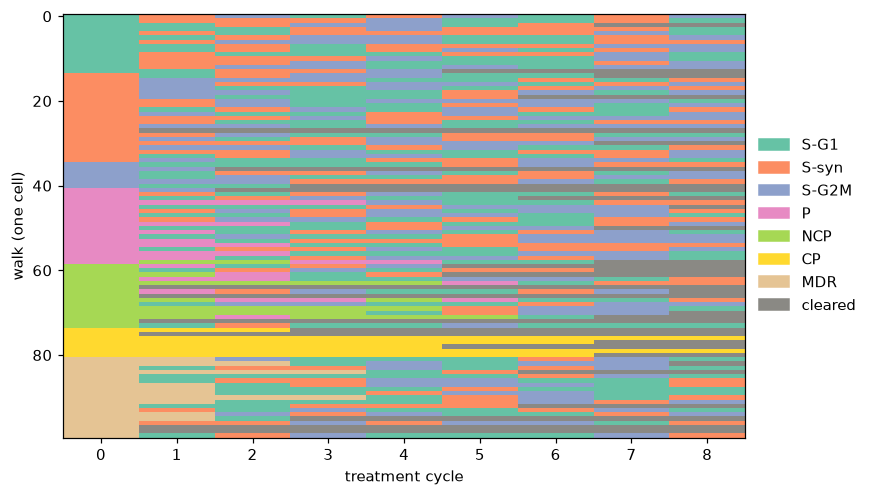

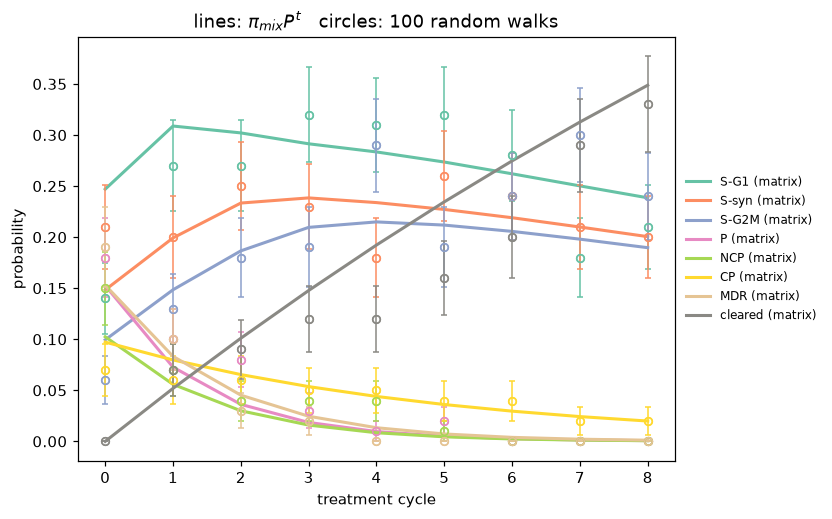

### N=10_000 Outputs

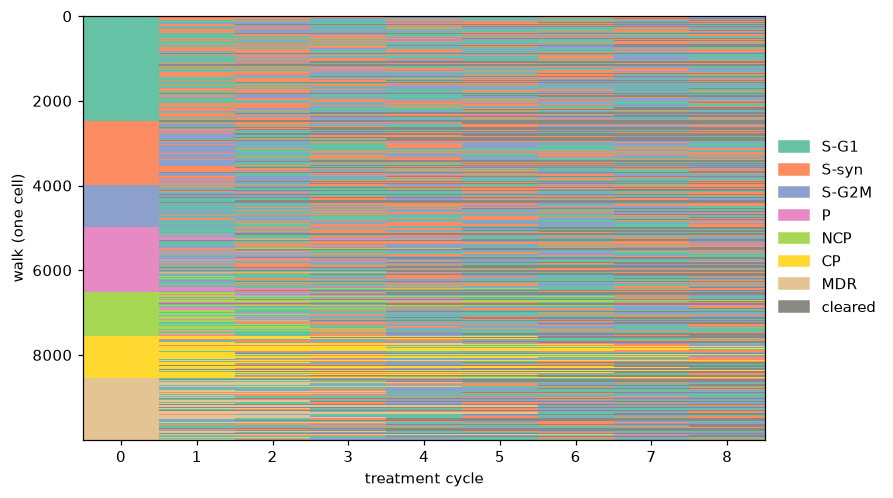

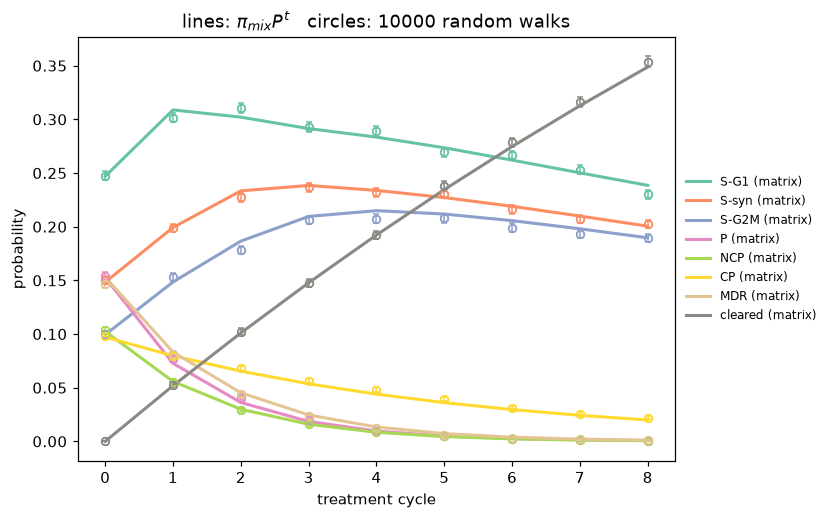

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

With 10,000 walks, the circles generally fall closer to the lines, and the error bars are much smaller. For example, at 4 cycles the gray line (cleared) predicts that about 19% or 20% of cells are cleared. The circle is around 12% with 100 walks and almost exactly on the line with 10,000 walks. Each circle represents a simulated proportion, so using more independent walks reduces sampling variability. This also explains why the error bars are much larger with 100 walks and barely visible with 10,000.

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [30]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

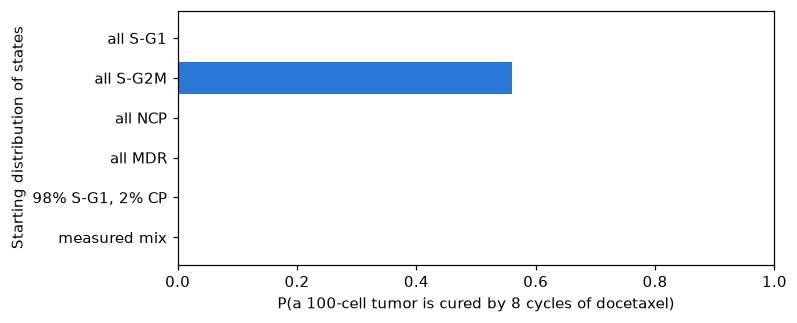

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.00,6.915,0.0
all S-G2M,0.56,0.575,0.0
all NCP,0.00,6.615,0.0
all MDR,0.00,100.000,0.0
"98% S-G1, 2% CP",0.00,6.950,0.0
measured mix,0.00,19.250,0.0


In [31]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8      # this simulation is 8 cycles of docetaxel now
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of docetaxel)") # I changed the label to docetaxel
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

Original Output

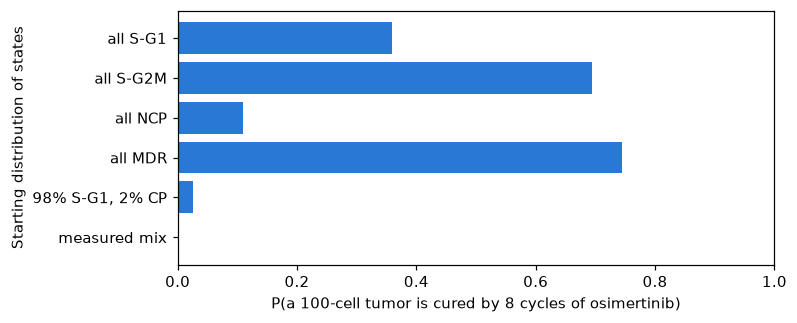

Original output

| Start | P(cured) | Mean surviving cells | Share of survivors that are CP |
|:------|---------:|---------------------:|-------------------------------:|
| all S-G1 | 0.360 | 1.030 | 0.000 |
| all S-G2M | 0.695 | 0.345 | 0.000 |
| all NCP | 0.110 | 2.135 | 0.000 |
| all MDR | 0.745 | 0.280 | 0.000 |
| 98% S-G1, 2% CP | 0.025 | 3.210 | 0.639 |
| measured mix | 0.000 | 10.665 | 0.919 

Docetaxel Output

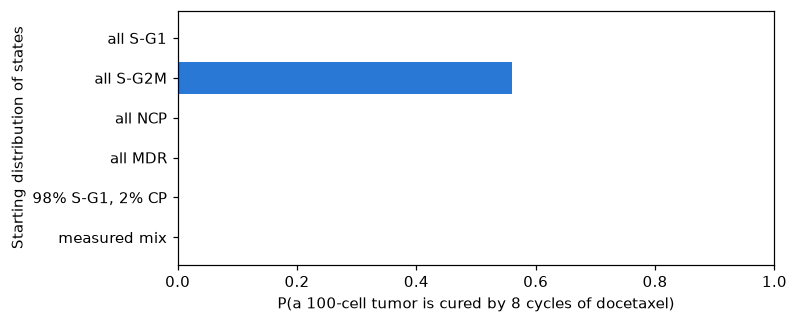

Docetaxel Output

| Start | P(cured) | Mean surviving cells | Share of survivors that are CP |
|:------|---------:|---------------------:|-------------------------------:|
| all S-G1 | 0.00 | 6.915 | 0.0 |
| all S-G2M | 0.56 | 0.575 | 0.0 |
| all NCP | 0.00 | 6.615 | 0.0 |
| all MDR | 0.00 | 100.000 | 0.0 |
| 98% S-G1, 2% CP | 0.00 | 6.950 | 0.0 |
| measured mix | 0.00 | 19.250 | 0.0 |

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

After eight cycles of docetaxel, only tumors starting entirely in S-G2M cleared completely, with 112 of 200 cured (56%). The S-G2M group was the only group that I observed a cure. All MDR tumors retained all 100 cells because MDR is absorbing under docetaxel. In comparison, osimertinib cured 74.5% of all MDR tumors. Neither drug cured a measured-mix tumor in this simulation. An average of 19.25 cells per tumor survived docetaxel, compared with 10.665 under osimertinib.

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [33]:
# write a function that runs 1000 random walks and saves them
# you will use this function 100 times to generate a simulated set of tumors
def tumor_walks(pi0, schedule, n_cells, rng):
    pr = len(OUTCOMES)
    persister_states = [OUTCOMES.index("P"), OUTCOMES.index("NCP")]
    paths = np.empty((n_cells, len(schedule) + 1), dtype=int)
    paths[:, 0] = rng.choice(len(OUTCOMES), size=n_cells, p=pi0)
    streak = np.zeros(n_cells, dtype=int)

# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
    for cycle, drug in enumerate(schedule, start=1):
        previous = paths[:, cycle - 1]
        current = previous.copy()

        for state, probabilities in enumerate(drugs[drug]):
            mask = previous == state
            current[mask] = rng.choice(len(OUTCOMES), size=mask.sum(), p=probabilities)

        in_persister = np.isin(current, persister_states)
        streak = np.where(in_persister, streak + 1, 0)
        current[streak >= 3] = pr
        paths[:, cycle] = current

    return paths

# count up cells that stayed in persister state consecutively out of total cells
def percent_pr(paths, cycle):
    pr = len(OUTCOMES)
    return 100 * np.mean(paths[:, cycle] == pr)

# repeat for all tumors
pr_rng = np.random.default_rng(5032)
n_cells = 1000
n_tumors = 100
check_cycles = [4, 8, 12, 16]

regimens = {
    "Osimertinib": "O" * 16, "Docetaxel": "D" * 16,
    "Alternating OD": "OD" * 8, "Docetaxel / holiday": "DH" * 8,}

rows = []
for name, schedule in regimens.items():
    for tumor in range(n_tumors):
        paths = tumor_walks(pi_mix, schedule, n_cells, pr_rng)

        for cycle in check_cycles:
            pr_percent = percent_pr(paths, cycle)
            rows.append([name, tumor, cycle, pr_percent, pr_percent > 10])

pr_results = pd.DataFrame(rows, columns=["schedule", "tumor", "cycle", "PR percent", "over 10%"])

# report mean +/- SEM for osimertinib
osi8 = pr_results.loc[(pr_results["schedule"] == "Osimertinib") & (pr_results["cycle"] == 8), "PR percent"]
mean_pr = osi8.mean()
sem_pr = osi8.sem()
print(f"Mean PR after 8 cycles of osimertinib: {mean_pr:.3f}%")
print(f"SEM: {sem_pr:.3f} percentage points")

# compare to 10% threshold using 95% CI or a hypothesis test
margin = 1.96 * sem_pr
print(f"Approximate 95% CI for mean PR: [{mean_pr - margin:.3f}%, {mean_pr + margin:.3f}%]")
print("Percentage of tumors with more than 10% PR cells")
100 * pr_results.pivot_table(index="schedule", columns="cycle", values="over 10%", aggfunc="mean")

Mean PR after 8 cycles of osimertinib: 8.169%
SEM: 0.085 percentage points
Approximate 95% CI for mean PR: [8.002%, 8.336%]
Percentage of tumors with more than 10% PR cells


cycle,4,8,12,16
schedule,,,,
Alternating OD,0.0,0.0,0.0,0.0
Docetaxel,0.0,0.0,0.0,0.0
Docetaxel / holiday,0.0,0.0,0.0,0.0
Osimertinib,0.0,1.0,1.0,1.0


<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

Under osimertinib alone, 0% of tumors had more than 10% permanently resistant (PR) cells after 4 cycles. By cycle 8, one of the 100 simulated tumors (1%) had crossed the threshold. Because PR is an absorbing state, that tumor remained above the threshold, and no additional tumors crossed it by cycles 12 or 16. Under docetaxel alone, 0% of tumors exceeded 10% PR at cycles 4, 8, 12, or 16. The same was true when alternating osimertinib and docetaxel and when alternating docetaxel with a drug holiday. Under all three schedules, the percentage stayed at 0% as the number of cycles increased. After 8 cycles of osimertinib, the mean percentage of PR cells per tumor was 8.169% +/- 0.085% (SEM). The approximate 95% confidence interval for the mean was 8.002% to 8.336%. The entire interval was below 10%, even though one individual tumor exceeded 10% PR.